<a href="https://colab.research.google.com/github/manvi-smaran/1024160111_UCS420_CC_Assignments/blob/main/1024160111_A8_UCS420.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
import re
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.probability import FreqDist

In [25]:
paragraph = "Artificial intelligence is transforming our modern world. Artificial intelligence and machine learning allow systems to learn. Deep learning uses neural networks to solve complex problems. Machine learning, deep learning, and artificial intelligence are changing everything rapidly. We must learn to adapt to artificial intelligence safely."

cleaned_text = re.sub(r'[^\w\s]', '', paragraph.lower())
print("Cleaned Text:", cleaned_text)

sentences = sent_tokenize(paragraph)
words_nltk = word_tokenize(cleaned_text)
print(f"\nSentences: {len(sentences)} | Words: {len(words_nltk)}")

Cleaned Text: artificial intelligence is transforming our modern world artificial intelligence and machine learning allow systems to learn deep learning uses neural networks to solve complex problems machine learning deep learning and artificial intelligence are changing everything rapidly we must learn to adapt to artificial intelligence safely

Sentences: 5 | Words: 45


In [26]:
words_split = cleaned_text.split()
print(f"Using split(): {len(words_split)} tokens")
print(f"Using NLTK word_tokenize(): {len(words_nltk)} tokens")

Using split(): 45 tokens
Using NLTK word_tokenize(): 45 tokens


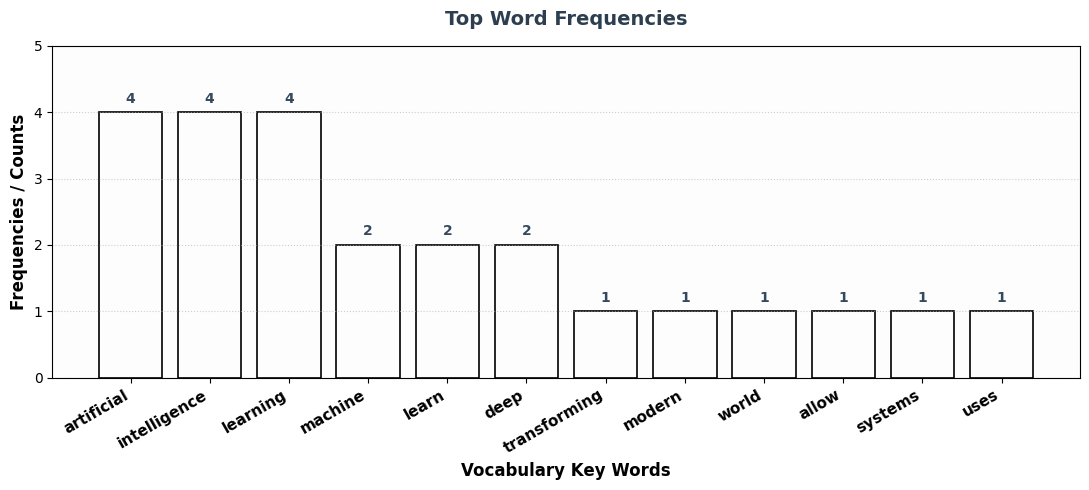

In [40]:
stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words_nltk if w not in stop_words]

fdist = FreqDist(filtered_words)
top_words = fdist.most_common(12)
words, counts = zip(*top_words)

plt.figure(figsize=(11, 5))
bars = plt.bar(words, counts, fill=False, edgecolor='black', linewidth=1.2)
plt.title("Top Word Frequencies", fontsize=14, fontweight='bold', pad=15, color='#2c3e50')
plt.ylabel("Frequencies / Counts", fontsize=12, fontweight='bold')
plt.xlabel("Vocabulary Key Words", fontsize=12, fontweight='bold')
plt.xticks(rotation=30, ha='right', fontsize=11, fontweight='semibold')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.gca().set_facecolor('#fdfdfd')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.1, str(yval), ha='center', va='bottom', fontsize=10, fontweight='bold', color='#34495e')

plt.ylim(0, max(counts) + 1)
plt.tight_layout()
plt.show()

### Q2. Stemming vs Lemmatization

In [28]:
alpha_words = re.findall(r'\b[a-zA-Z]+\b', paragraph.lower())
filtered_alpha = [w for w in alpha_words if w not in stop_words]

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

comparison = pd.DataFrame({
    'Original': filtered_alpha,
    'Stemmed': [stemmer.stem(w) for w in filtered_alpha],
    'Lemmatized': [lemmatizer.lemmatize(w) for w in filtered_alpha]
})
display(comparison.head(10))

,Original,Stemmed,Lemmatized
0,artificial,artifici,artificial
1,intelligence,intellig,intelligence
2,transforming,transform,transforming
3,modern,modern,modern
4,world,world,world
5,artificial,artifici,artificial
6,intelligence,intellig,intelligence
7,machine,machin,machine
8,learning,learn,learning
9,allow,allow,allow


**Comparison Explanation**:
- **Stemming** chops suffix endings based on heuristic rules (e.g., 'transforming' -> 'transform', 'technologies' -> 'technolog'). It is extremely fast but can produce non-dictionary terms.
- **Lemmatization** uses morphological analysis to return valid base dictionary words (e.g., 'technologies' -> 'technology'). It preserves exact lexical meanings but requires part-of-speech context and extra compute.

### Q3. Vectorization (BoW & TF-IDF)

In [29]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "The new smartphone has an incredible camera and battery life.",
    "The battery life of this smartphone is very disappointing and terrible.",
    "I love taking photos with the high-resolution camera on my new phone."
]

cv = CountVectorizer(stop_words='english')
bow_matrix = cv.fit_transform(texts)

tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(texts)

features = tfidf.get_feature_names_out()
for i, row in enumerate(tfidf_matrix.toarray()):
    top_indices = np.argsort(row)[::-1][:3]
    print(f"Text {i+1} top keywords: {[features[idx] for idx in top_indices]}")

Text 1 top keywords: ['incredible', 'smartphone', 'battery']
Text 2 top keywords: ['terrible', 'disappointing', 'life']
Text 3 top keywords: ['taking', 'resolution', 'phone']


### Q4. Text Similarity

In [30]:
from sklearn.metrics.pairwise import cosine_similarity

tech_ai = "Artificial intelligence processes digital data to simulate human reasoning, learning, and automated decision making."
tech_bc = "Blockchain uses a secure distributed ledger to record digital transactions without a central authority."

set_ai = set(word_tokenize(re.sub(r'[^\w\s]', '', tech_ai.lower())))
set_bc = set(word_tokenize(re.sub(r'[^\w\s]', '', tech_bc.lower())))

jaccard_sim = len(set_ai.intersection(set_bc)) / len(set_ai.union(set_bc))

vectorizer = TfidfVectorizer(stop_words='english')
tfidf_sim = vectorizer.fit_transform([tech_ai, tech_bc])
cos_sim = cosine_similarity(tfidf_sim[0], tfidf_sim[1])[0][0]

print(f"Jaccard Similarity: {jaccard_sim:.4f}")
print(f"Cosine Similarity: {cos_sim:.4f}")

Jaccard Similarity: 0.0800
Cosine Similarity: 0.0484


**Analysis**: Cosine Similarity provides better insights here. Jaccard is binary and penalizes stylistic length and vocabulary differences harshly, whereas Cosine with TF-IDF weights core terms properly to find semantic alignment.

### Q5. Sentiment & Word Cloud

In [31]:
from textblob import TextBlob
from wordcloud import WordCloud

reviews = [
    "This product is absolutely wonderful, highly recommended and extremely easy to use!",
    "Terrible experience. The build quality is cheap and it broke down within two days.",
    "The service is average, not too bad but definitely has room for improvement.",
    "Outstanding performance and brilliant design. I am thoroughly happy with this purchase.",
    "Very disappointed with the product. It was delayed and arrived damaged."
]

results = []
positive_text = ""
for r in reviews:
    blob = TextBlob(r)
    pol, subj = blob.sentiment.polarity, blob.sentiment.subjectivity
    label = 'Positive' if pol > 0.1 else ('Negative' if pol < -0.1 else 'Neutral')
    if label == 'Positive':
        positive_text += " " + r
    results.append((r, pol, subj, label))

df_reviews = pd.DataFrame(results, columns=['Review', 'Polarity', 'Subjectivity', 'Sentiment'])
display(df_reviews)

,Review,Polarity,Subjectivity,Sentiment
0,"This product is absolutely wonderful, highly r...",0.567222,0.791111,Positive
1,Terrible experience. The build quality is chea...,-0.251852,0.662963,Negative
2,"The service is average, not too bad but defini...",-0.283333,0.522222,Negative
3,Outstanding performance and brilliant design. ...,0.733333,0.958333,Positive
4,Very disappointed with the product. It was del...,-0.975000,0.975000,Negative


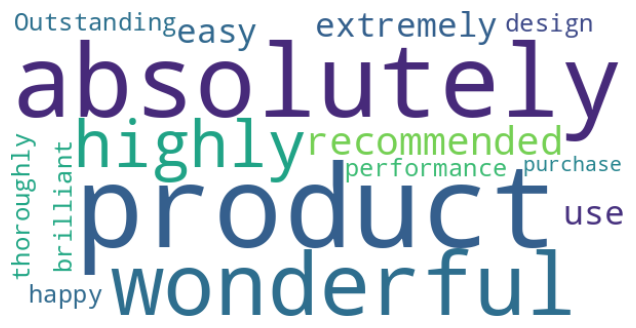

In [38]:
wc = WordCloud(background_color='white', width=600, height=300).generate(positive_text)
plt.figure(figsize=(8, 4))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.show()

### Q6. Text Generation Model

In [45]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

training_para = "Natural language processing and deep learning are core drivers of today's artificial intelligence tools. Deep neural networks learn directly from sequential datasets like text. This sequential learning enables computers to generate human-like sentences iteratively. By training models on representative corpora, developers can generate coherent next word predictions with high accuracy."

tok = Tokenizer()
tok.fit_on_texts([training_para])
total_words = len(tok.word_index) + 1

input_seqs = []
for sentence in training_para.split('.'):
    tokens = tok.texts_to_sequences([sentence])[0]
    for i in range(1, len(tokens)):
         input_seqs.append(tokens[:i+1])

max_len = max([len(x) for x in input_seqs])
input_seqs = np.array(pad_sequences(input_seqs, maxlen=max_len, padding='pre'))

X, y = input_seqs[:,:-1], tf.keras.utils.to_categorical(input_seqs[:,-1], num_classes=total_words)

In [46]:
model = Sequential([
    Embedding(total_words, 32),
    LSTM(50),
    Dense(total_words, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(X, y, epochs=120, verbose=0)

seed = "deep"
for _ in range(3):
    seq = pad_sequences(tok.texts_to_sequences([seed]), maxlen=max_len-1, padding='pre')
    pred = np.argmax(model.predict(seq, verbose=0), axis=-1)[0]
    next_word = [word for word, idx in tok.word_index.items() if idx == pred]
    if next_word:
        seed += " " + next_word[0]

print("Generated text:", seed)

Generated text: deep sequential sequential learning
